# Case Study: Does Age Influence Playing Time in La Liga?

In this case study, I investigate whether there is a relationship between **player age and minutes played** in La Liga. The data was obtained from [FBref](https://fbref.com/en/comps/12/2021-2022/stats/2021-2022-La-Liga-Stats), using player statistics from the **2021–2022 La Liga season**.

For the analysis, I focus on two variables: **age** and **minutes played**. I first explore the relationship visually using a scatter plot and then use **linear and polynomial regression models** to assess whether a player's age can help explain their playing time.

The objective is not to claim that age determines playing time, but rather to examine whether there is a **statistical relationship** between the two variables and how well age can explain differences in playing minutes among La Liga players.

In [31]:
# importing the necessary libries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

* we are using a data downloaded from FBref on players in La iga.
* we need columns of age and minutes. i will consider using the entire dataset.

In [28]:
num_obs = 1000
df =pd.read_csv(r"C:\Users\lamin\Downloads\playerstats.csv",delimiter=',')

# Create the dataset for the minutes model
minutes_model = pd.DataFrame({
    'minutes': df['Min'].iloc[:num_obs],
    'age': df['Age'].iloc[:num_obs]
})

# Create age-squared variable for the polynomial model
minutes_model['age_squared'] = minutes_model['age'] ** 2

# Display the model dataset
minutes_model.describe()


,minutes,age,age_squared
count,617.000000,616.000000,616.000000
mean,1217.071313,25.935065,694.318182
std,962.549041,4.661101,245.791681
min,1.000000,16.000000,256.000000
25%,295.000000,22.000000,484.000000
50%,1105.000000,26.000000,676.000000
75%,1890.000000,29.000000,841.000000
max,3420.000000,40.000000,1600.000000


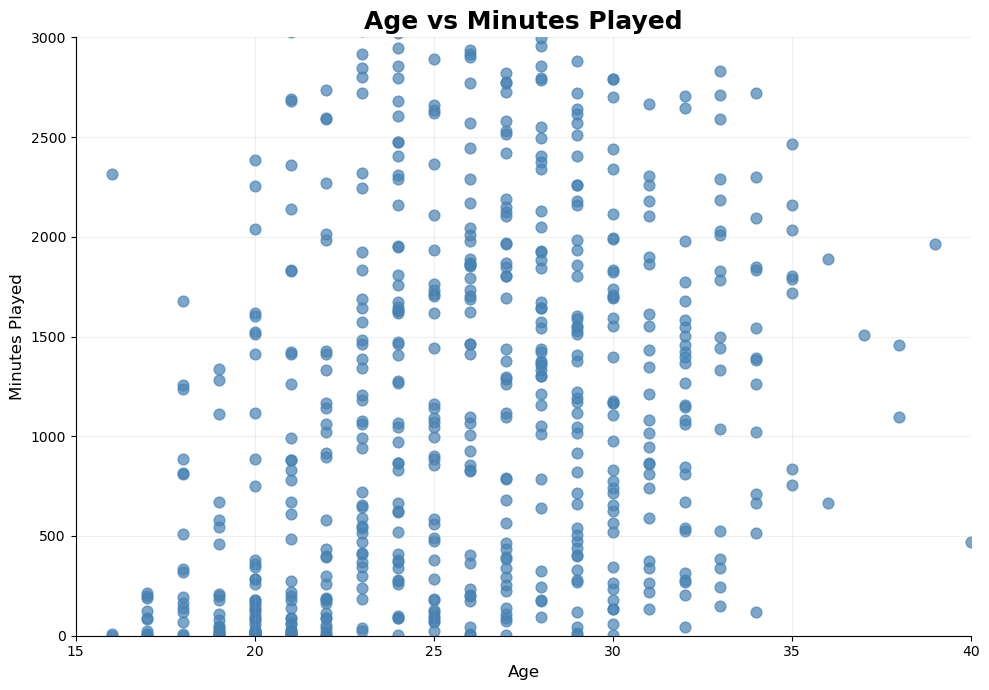

In [29]:
fig, ax = plt.subplots(figsize=(10, 7))

fig.set_facecolor("white")
ax.set_facecolor("white")

ax.scatter(
    minutes_model["age"],
    minutes_model["minutes"],
    s=60,
    alpha=0.7,
    color="steelblue",
    zorder= 1
)

ax.set_title("Age vs Minutes Played", fontsize=18, fontweight="bold")
ax.set_xlabel("Age", fontsize=12)
ax.set_ylabel("Minutes Played", fontsize=12)

ax.set_xlim(15, 40)
ax.set_ylim(0, 3000)

ax.grid(alpha=0.2)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

# fitting the a Quadratic model

                            OLS Regression Results                            
Dep. Variable:                minutes   R-squared:                       0.143
Model:                            OLS   Adj. R-squared:                  0.141
Method:                 Least Squares   F-statistic:                     51.35
Date:                Mon, 14 Sep 2026   Prob (F-statistic):           2.41e-21
Time:                        23:28:02   Log-Likelihood:                -5057.4
No. Observations:                 616   AIC:                         1.012e+04
Df Residuals:                     613   BIC:                         1.013e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept   -5255.8833    951.226     -5.525      

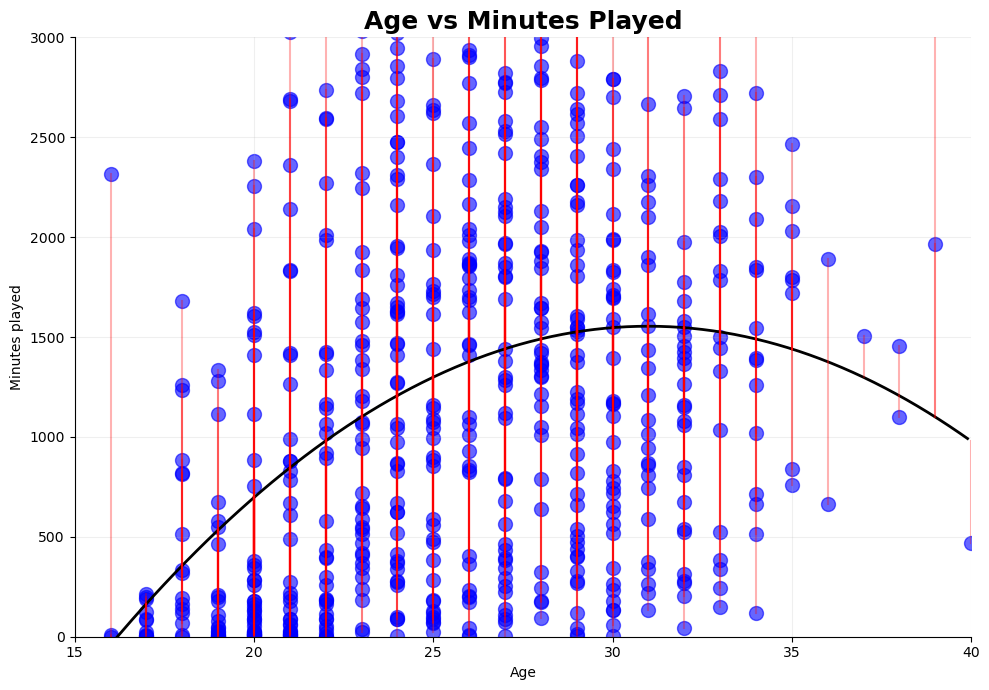

In [30]:
# Fit polynomial regression model
model_fit = smf.ols(
    formula="minutes ~ age + age_squared",
    data=minutes_model
).fit()

print(model_fit.summary())

# Get model coefficients
b = model_fit.params.values

# Create figure
fig, ax = plt.subplots(figsize=(10, 7))

# Plot players
ax.scatter(
    minutes_model["age"],
    minutes_model["minutes"],
    s=100,
    alpha=0.6,
    color="blue"
)

# Create fitted polynomial curve
x = np.arange(15, 40, 0.1)
y = b[0] + b[1] * x + b[2] * x**2

ax.plot(x, y, color="black", linewidth=2)

# Plot residuals
for i, age in enumerate(minutes_model["age"]):
    predicted = b[0] + b[1] * age + b[2] * age**2
    
    ax.plot(
        [age, age],
        [minutes_model["minutes"].iloc[i], predicted],
        color="red",
        alpha=0.3
    )

# Labels
ax.set_title("Age vs Minutes Played", fontsize=18, fontweight="bold")
ax.set_xlabel("Age")
ax.set_ylabel("Minutes played")

# Limits
ax.set_xlim(15, 40)
ax.set_ylim(0, 3000)

# Grid and styling
ax.grid(alpha=0.2)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

# key takings
* Players' minutes generally increase with age during the early stages of their careers, reach a peak, and then decline at older ages. However, age alone explains only 14.3% of playing-time differences.
### R² = 0.143 ⚽

Age explains about **14.3% of the variation in playing minutes**.

This means that **age matters**, but it is definitely **not the main factor** determining how many minutes a player gets.

Other factors such as **injuries, manager preference, player quality, position, transfers, and competition for places** can also have a major influence on playing time.